# Medicaid prescription spending

A reproducible healthcare analytics case study using an archived 2024 extract.

**Scope:** 11 states and Washington, DC. **Primary questions:** where does reported spending concentrate, and what data-quality constraints shape interpretation?

The original ASU project was completed by Annie Qin, Marcello Borromeo, Dhruv Nair and Mo Mia. This subsequent portfolio refinement preserves the original submission and documents its changes.

In [1]:
from pathlib import Path
import sys
import json
import sqlite3
import pandas as pd

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/medicaid_analytics").exists())
sys.path.insert(0, str(ROOT / "src"))
from medicaid_analytics.pipeline import run
from medicaid_analytics.verify import verify
if not (ROOT / "data/processed/analytics.sqlite").exists():
    run(ROOT)
audit = json.loads((ROOT / "reports/audit.json").read_text())
connection = sqlite3.connect(ROOT / "data/processed/analytics.sqlite")
print(audit["scope"])


Archived 2024 extract: 11 states and Washington, DC; not national


## 1. Audit the retained source before interpreting results

Both utilization sheets reach Excel's maximum populated row. Suppression means the reported dollar total excludes unknown amounts. It is not a national or complete net-spending estimate.

In [2]:
summary = pd.Series({
    "Retained records": audit["utilization"]["source_records"],
    "Suppressed records": audit["utilization"]["suppressed_records"],
    "Reported spending records": audit["utilization"]["spend_eligible_records"],
    "Reported pre-rebate reimbursement": audit["headline"]["total_reimbursement"],
    "Original/cleaned fact rows reconcile": audit["original_source_reconciliation"]["order_independent_fact_rows_match"],
    "Metadata matched share of dollars": audit["join"]["matched_spending_share"],
})
print(summary.to_string())
print("Jurisdictions:", ", ".join(audit["utilization"]["observed_states"]))


Retained records                                   1048575
Suppressed records                                  543945
Reported spending records                           504630
Reported pre-rebate reimbursement       27539974390.900002
Original/cleaned fact rows reconcile                  True
Metadata matched share of dollars                 0.994159
Jurisdictions: AK, AL, AR, AZ, CA, CO, CT, DC, DE, FL, GA, HI


## 2. Rank spending with SQL

The query uses `ROW_NUMBER`, cumulative window sums, and a denominator that includes unmatched metadata. Product keys combine package sizes; repeated product names can represent distinct product codes.

In [3]:
product_sql = (ROOT / "sql/product_spending.sql").read_text()
products = pd.read_sql_query(product_sql, connection)
print(products.head(10)[["product_key", "product_name", "reimbursement", "spend_share"]].to_string(index=False))
print(f"Top 10 share: {products.head(10).spend_share.sum():.1%}")
print(f"Top 50 share: {products.head(50).spend_share.sum():.1%}")


product_key    product_name  reimbursement  spend_share
  619582501        Biktarvy   907888446.52     0.032966
  000740554          Humira   633429714.83     0.023000
  001694181         Ozempic   527796714.03     0.019165
  001694130         Ozempic   404945247.57     0.014704
  504580564 INVEGA SUSTENNA   397690422.18     0.014440
  005970153       Jardiance   378817703.56     0.013755
  000245915        Dupixent   346782739.48     0.012592
  001694772         Ozempic   321640777.32     0.011679
  578940061         STELARA   305253951.05     0.011084
  005970152       Jardiance   290855662.37     0.010561
Top 10 share: 16.4%
Top 50 share: 37.1%


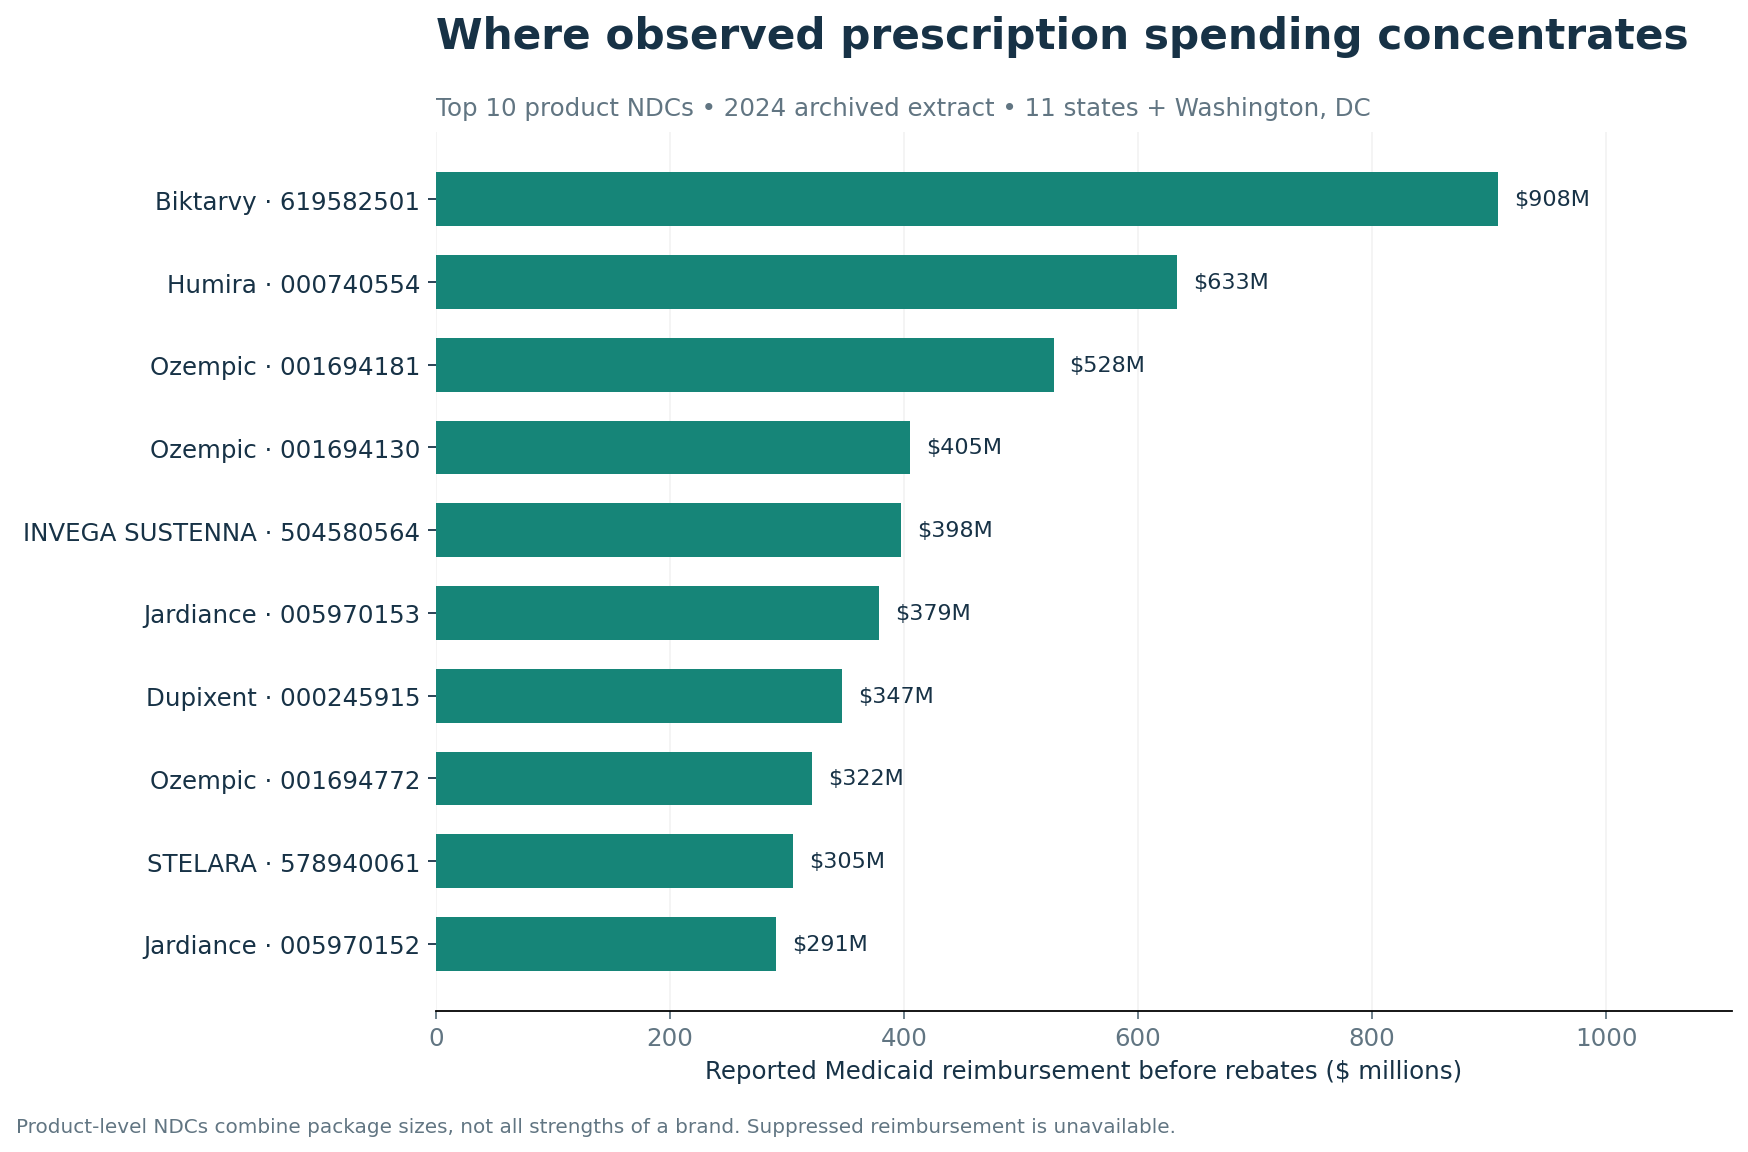

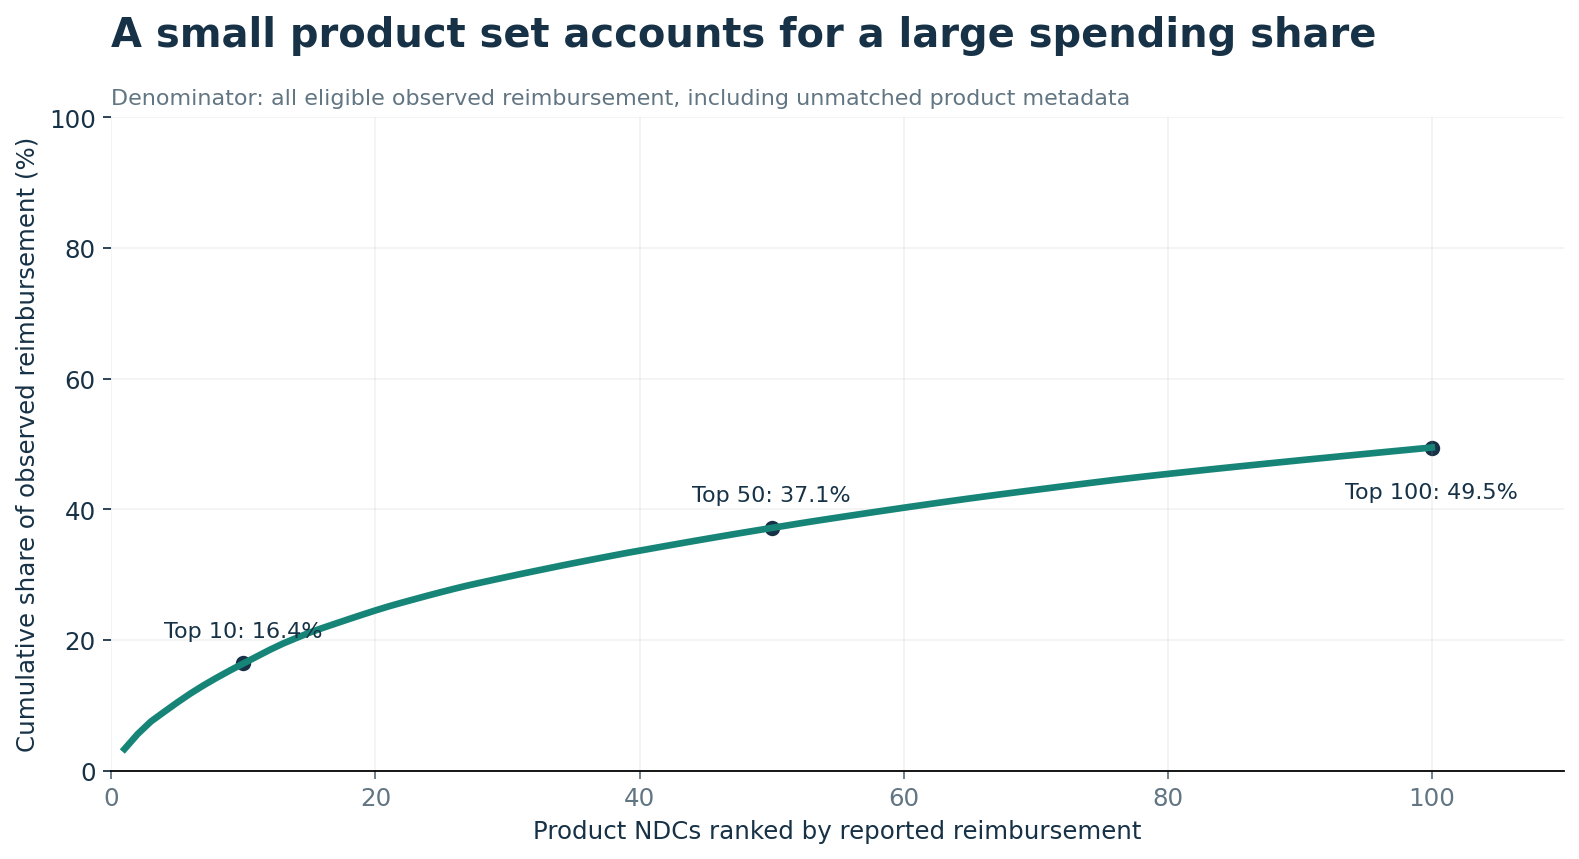

## 3. Assess coverage and quarterly patterns

Absolute jurisdiction amounts do not measure efficiency. Suppressed record shares do not estimate missing dollars. No Midwest jurisdiction is retained. Quarterly changes are descriptive and are not attributed to policy interventions.

In [4]:
coverage = pd.read_sql_query((ROOT / "sql/jurisdiction_coverage.sql").read_text(), connection)
quarters = pd.read_sql_query((ROOT / "sql/quarterly_spending.sql").read_text(), connection)
print(coverage[["state", "source_records", "suppressed_record_share", "reimbursement"]].to_string(index=False))
print("\nQuarterly results:")
print(quarters.to_string(index=False))


state  source_records  suppressed_record_share  reimbursement
   CA          160323                 0.394466   1.555446e+10
   FL          124606                 0.497167   3.164141e+09
   CT           71030                 0.463903   1.920175e+09
   AZ           95905                 0.529670   1.849963e+09
   CO           95583                 0.541969   1.453885e+09
   GA          127780                 0.489161   1.241096e+09
   AL           68739                 0.472148   1.000427e+09
   AR           90130                 0.546377   4.580015e+08
   DC           74971                 0.724560   2.469271e+08
   DE           59686                 0.637603   2.404785e+08
   HI           36236                 0.577188   2.053755e+08
   AK           43586                 0.589731   2.050482e+08

Quarterly results:
 quarter  reimbursement  spend_eligible_records  prescriptions  reimbursement_per_prescription  quarter_change
       1   6.700734e+09                  124167     45923839.0 

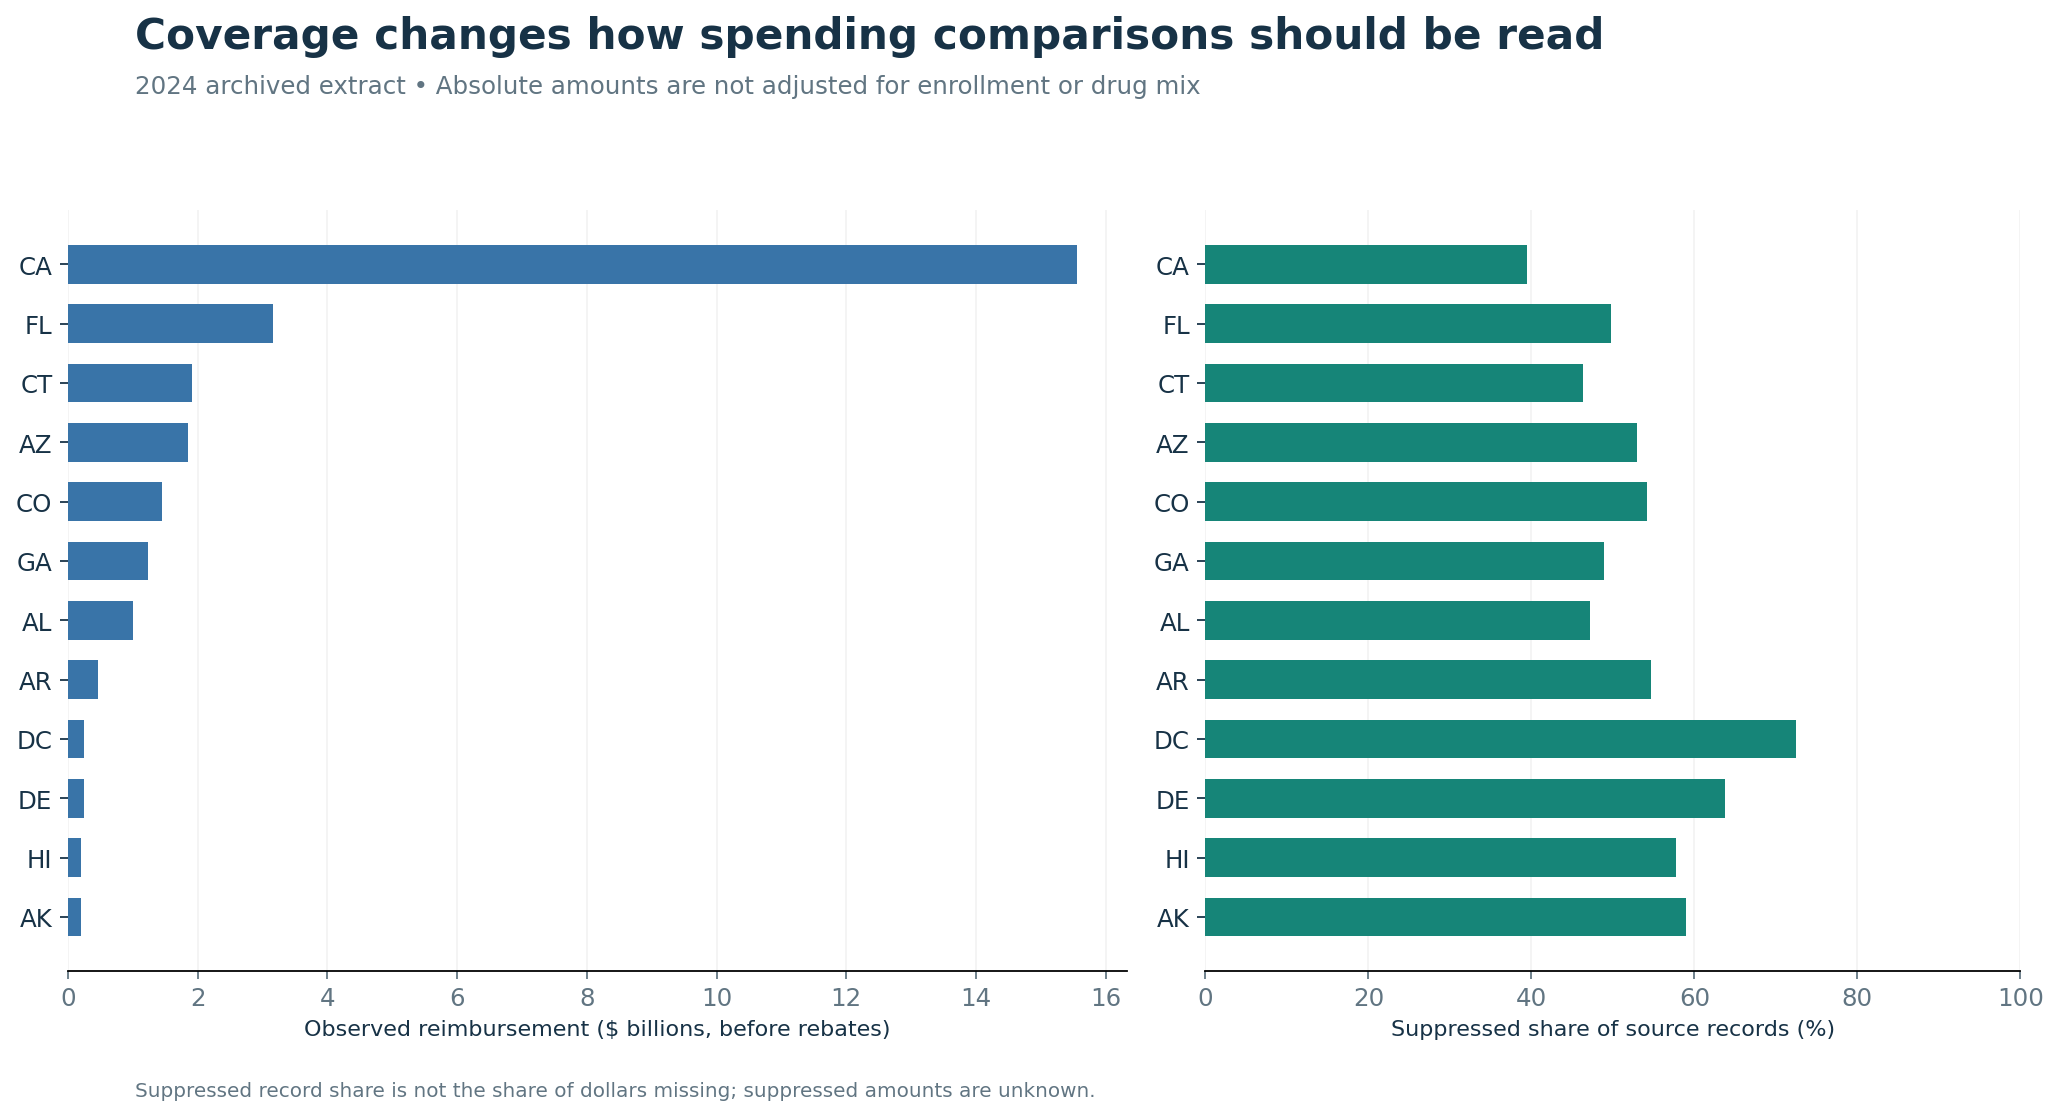

## 4. Reproduce and challenge the original Q3 result

The original ingredient-level calculations reproduce to the cent. However, name-based brand labels, ingredient-only grouping, rounded prices and unsupported adoption assumptions prevent those figures from establishing practical or net savings.

In [5]:
legacy = audit["legacy_reproduction"]
for key in ["legacy_median_scenario", "legacy_weighted_scenario", "legacy_class_adjusted_scenario"]:
    print(f"{key}: ${legacy[key]:,.2f}")
print(f"Paper's approximate class-adjusted claim: ${legacy['paper_claimed_class_adjusted_scenario']:,.0f}")


legacy_median_scenario: $1,824,211,090.03
legacy_weighted_scenario: $1,752,285,190.51
legacy_class_adjusted_scenario: $987,704,842.04
Paper's approximate class-adjusted claim: $1,200,000,000


## 5. A narrower price-review screen

NDA- and ANDA-listed prescription products are compared within identical recorded ingredient, strength, strength unit, dosage form, route, jurisdiction, quarter and utilization type. Reimbursement-weighted prices are ratios of sums. Marketing-date overlap is checked. This is **not an equivalence determination or net-savings estimate**. Unit types, rebates and feasibility remain unverified.

In [6]:
screen = audit["reimbursement_gap_screening"]
print("Paired formulations:", screen["distinct_paired_formulations"])
print("Paired reporting strata:", screen["paired_strata"])
print(f"Illustrative positive gross reimbursement gap: ${screen['illustrative_positive_gross_gap']:,.2f}")
print(f"Signed gap including negative comparisons: ${screen['signed_gross_gap']:,.2f}")
print(screen["interpretation"])
ranking = pd.read_csv(ROOT / "reports/tables/formulation_gap_ranking.csv")
print(ranking.head(5)[["ingredient", "dosage_form", "strength", "strength_unit", "positive_gross_gap"]].to_string(index=False))


Paired formulations: 562
Paired reporting strata: 6675
Illustrative positive gross reimbursement gap: $516,161,761.37
Signed gap including negative comparisons: $506,733,293.57
Illustrative pre-rebate reimbursement-gap screening; not verified substitution or net savings.
                           ingredient              dosage_form strength strength_unit  positive_gross_gap
                         cyclosporine                 emulsion      0.5         mg/ml        4.450206e+07
          lisdexamfetamine dimesylate                  capsule       30          mg/1        2.282819e+07
        methylphenidate hydrochloride tablet, extended release       36          mg/1        2.233701e+07
          lisdexamfetamine dimesylate                  capsule       40          mg/1        1.921478e+07
fluticasone propionate and salmeterol                   powder  250; 50    ug/1; ug/1        1.904768e+07


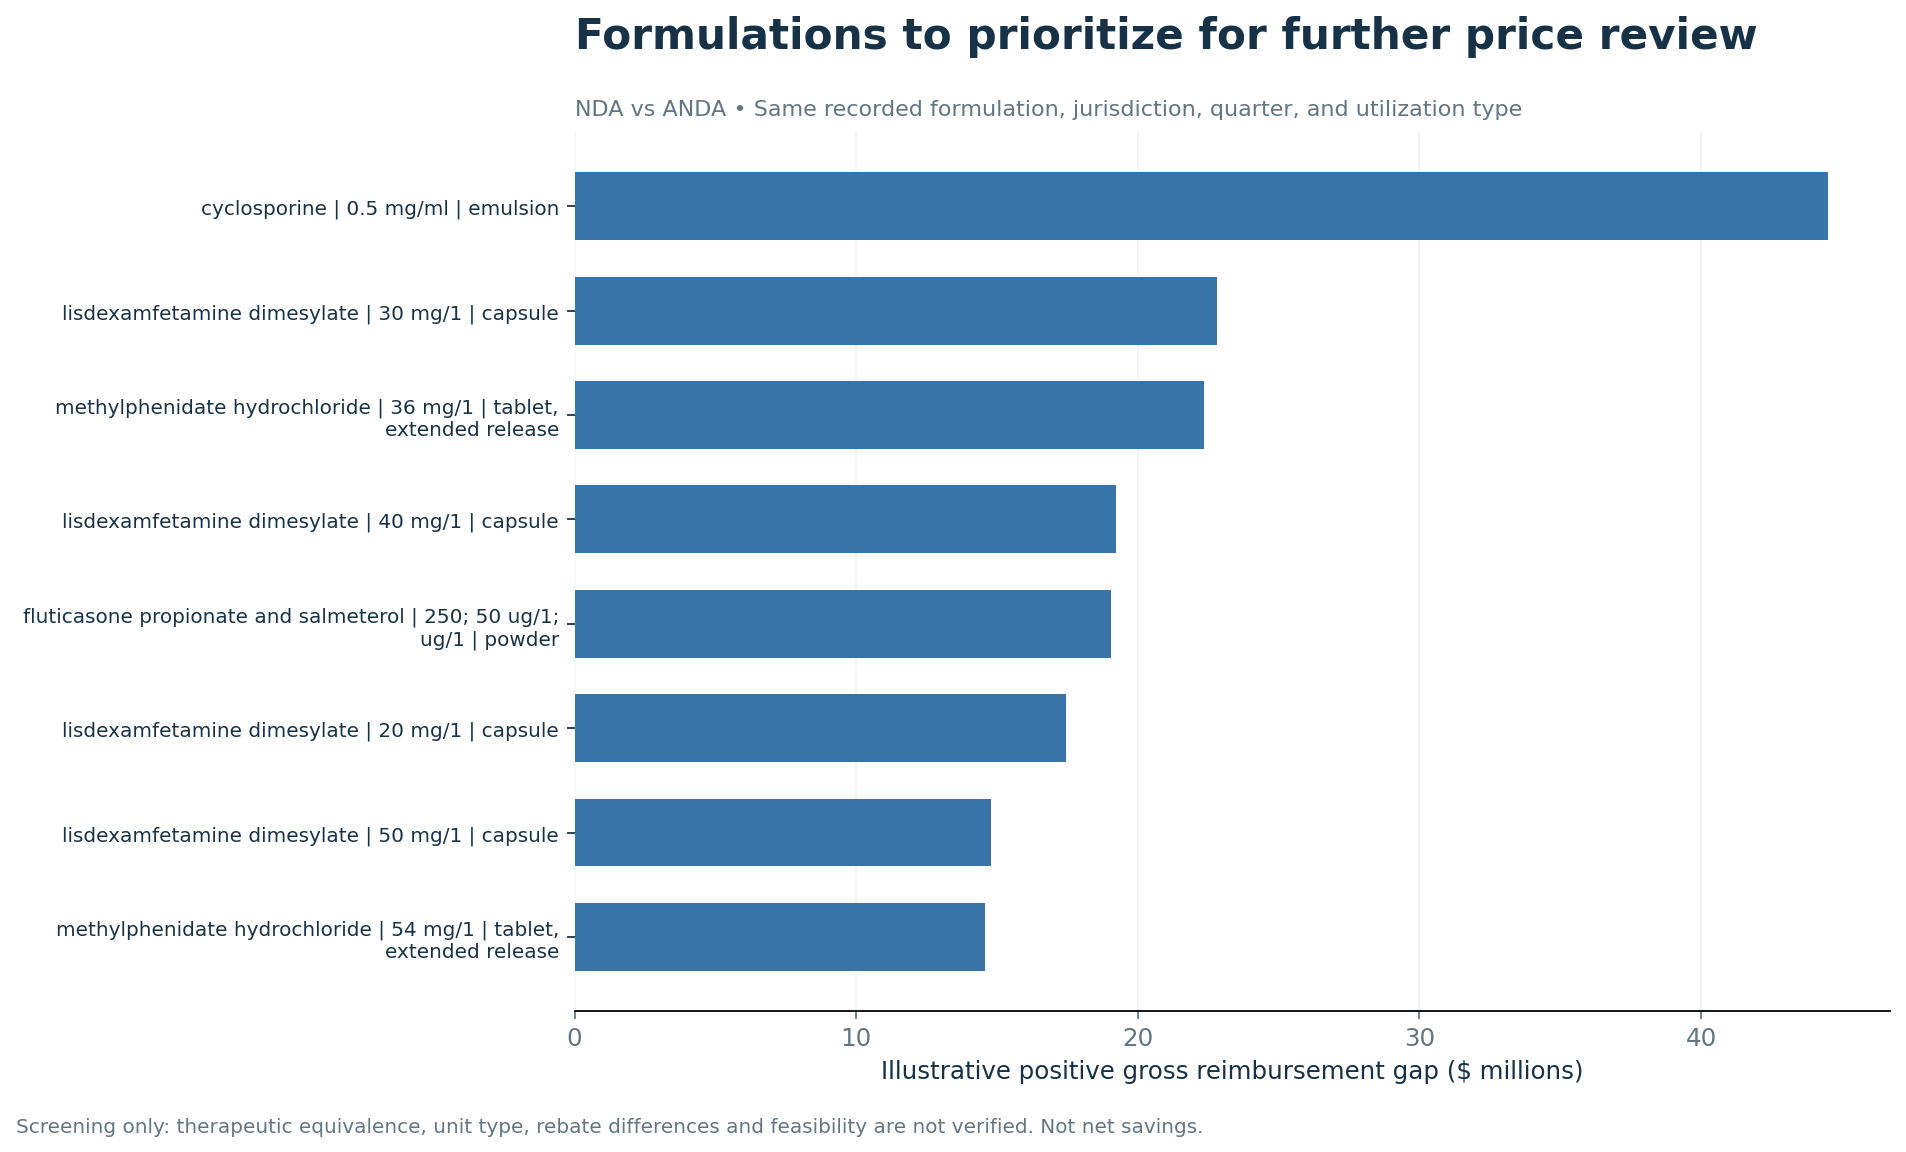

## 6. Validation and decision boundary

Prioritize high-dollar products for investigation. Before proposing interventions, obtain complete dated source coverage, unit types, appropriate FDA equivalence references, net rebate effects and stakeholder review. No new machine-learning model is needed for this descriptive decision.

See `docs/METHODOLOGY.md`, `docs/AUDIT_REPORT.md` and `data/README.md` for detailed definitions and limitations.

In [7]:
verify(ROOT)
connection.close()


PASS: input hashes, original row reconciliation, SQL totals, coverage, gap bounds, and preserved archive files
